# Lab 06 — Randomness, RNG Testing and Random Walks

**Objectives**

1. Implement a pseudo-random number generator (PRNG).
2. Generate uniform random numbers in $[0, 1)$.
3. Evaluate the quality of a PRNG using statistical tests.
4. Apply Chi-square tests to assess uniformity.
5. Perform a spectral analysis to detect lattice structures.
6. Compare custom generators with the language native RNG.
7. Simulate and analyze the Drunkard's Walk problem (2D and 3D).

The implementation lives in plain Python modules next to this notebook:

| module | content |
|---|---|
| `lcg.py` | Linear congruential generator, Hull–Dobell check, jump-ahead, Schrage's method, the generators of the slides |
| `chi_square.py` | Chi-square uniformity test and its variants: serial, gap and runs-up tests |
| `spectral.py` | Spectral test (dual lattice + LLL + exact shortest-vector search) |
| `random_walk.py` | Vectorised lattice random walk in $\mathbb{Z}^2$ / $\mathbb{Z}^3$ |

In [5]:
import random
import time
from math import atan2, degrees

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

from lcg import (LCG, LCGStreams, hull_dobell, prime_factors, schrage_next,
                 slides_lcg16, lcg32, minstd, simscript, randu)
from chi_square import (chi_square_uniformity, serial_test, gap_test, gap_lengths,
                        runs_up_test, runs_up_counts)
from spectral import spectral_test, overlapping_tuples
from random_walk import simulate_walks, expected_mean_distance, POLYA_3D

plt.rcParams["figure.dpi"] = 110

## 1. Implementing a PRNG: the Linear Congruential Generator

$$Z_i = (a\,Z_{i-1} + c) \bmod m, \qquad U_i = Z_i / m \in [0,1)$$

* $m$ modulus, $a$ multiplier, $c$ increment, $Z_0$ seed; $0 \le Z_i \le m-1$.
* $c>0$: **mixed** LCG, $c=0$: **multiplicative** LCG.
* **Hull–Dobell theorem**: a mixed LCG has full period $m$ iff (i) $\gcd(c,m)=1$, (ii) every prime $q \mid m$ divides $a-1$, (iii) $4 \mid m \Rightarrow 4 \mid a-1$. Guaranteed by $m=2^b$, $a=4k+1$, $c$ odd.

**Validation against the slides**: full-cycle example $m=16, a=5, c=3, Z_0=7$.

In [6]:
g = slides_lcg16()
u = [g.random() for _ in range(19)]
slides_table = [0.375, 0.063, 0.500, 0.688, 0.625, 0.313, 0.750, 0.938, 0.875, 0.563,
                0.000, 0.188, 0.125, 0.813, 0.250, 0.438, 0.375, 0.063, 0.500]

for i, (ui, si) in enumerate(zip(u, slides_table), start=1):
    print(f"i={i:2d}  U={ui:.3f}  slides={si:.3f}")
assert np.allclose(np.round(u, 3), slides_table, atol=1e-3)

print("\nperiod      :", g.period())
print("Hull-Dobell :", hull_dobell(16, 5, 3))

# 4-bit word example of the slides: Z0=5, a=5, c=3 -> (5*5+3)=28=11100b -> keep 4 bits 1100b = 12
print("4-bit example Z1 =", LCG(16, 5, 3, 5).next_int())

i= 1  U=0.375  slides=0.375
i= 2  U=0.062  slides=0.063
i= 3  U=0.500  slides=0.500
i= 4  U=0.688  slides=0.688
i= 5  U=0.625  slides=0.625
i= 6  U=0.312  slides=0.313
i= 7  U=0.750  slides=0.750
i= 8  U=0.938  slides=0.938
i= 9  U=0.875  slides=0.875
i=10  U=0.562  slides=0.563
i=11  U=0.000  slides=0.000
i=12  U=0.188  slides=0.188
i=13  U=0.125  slides=0.125
i=14  U=0.812  slides=0.813
i=15  U=0.250  slides=0.250
i=16  U=0.438  slides=0.438
i=17  U=0.375  slides=0.375
i=18  U=0.062  slides=0.063
i=19  U=0.500  slides=0.500

period      : 16
Hull-Dobell : (True, {'gcd(c, m) = 1': True, 'q | m  =>  q | a-1': True, '4 | m  =>  4 | a-1': True})
4-bit example Z1 = 12


### Full period or not?

Period found by cycle detection compared with the Hull–Dobell prediction. Multiplicative generators ($c=0$) can never reach period $m$ (0 is a fixed point), as stated in the slides; their maximum is $m-1$ when $m$ is prime and $a$ is a primitive root.

In [7]:
small = [(16, 5, 3), (16, 5, 2), (16, 7, 3), (16, 4, 3), (64, 13, 1), (64, 13, 0), (13, 2, 0), (13, 3, 0)]
print(f"{'m':>4} {'a':>4} {'c':>3} | {'period':>6} | Hull-Dobell full period?")
for m, a, c in small:
    gen = LCG(m, a, c, seed=1)
    full, _ = hull_dobell(m, a, c)
    print(f"{m:4d} {a:4d} {c:3d} | {gen.period():6d} | {full}")

# The two power-of-2 mixed LCGs used later: same construction, very different m
for g in (LCG(256, 101, 1, 0), lcg32()):
    print(f"\n{g.name}: Hull-Dobell ->", hull_dobell(g.m, g.a, g.c))
print("LCG(256,101,1) period:", LCG(256, 101, 1, 0).period())

   m    a   c | period | Hull-Dobell full period?
  16    5   3 |     16 | True
  16    5   2 |      8 | False
  16    7   3 |      4 | False
  16    4   3 |      1 | False
  64   13   1 |     64 | True
  64   13   0 |     16 | False
  13    2   0 |     12 | False
  13    3   0 |      3 | False

LCG(m=256, a=101, c=1): Hull-Dobell -> (True, {'gcd(c, m) = 1': True, 'q | m  =>  q | a-1': True, '4 | m  =>  4 | a-1': True})

LCG(2^32): Hull-Dobell -> (True, {'gcd(c, m) = 1': True, 'q | m  =>  q | a-1': True, '4 | m  =>  4 | a-1': True})
LCG(256,101,1) period: 256


### Avoiding overflow: Schrage's method

For a multiplicative LCG with $m = 2^{31}-1$ the product $a Z$ does not fit in 32 bits. Schrage's method ($q = \lfloor m/a \rfloor$, $r = m \bmod a$, $k = \lfloor Z/q \rfloor$, $Z' = a(Z - kq) - rk$, add $m$ if negative) keeps every intermediate value below $m$. Python integers never overflow, so we use it to check that both computations agree.

In [8]:
g = minstd()
z = g.seed
for _ in range(100_000):
    z = schrage_next(z, g.a, g.m)
    assert z == g.next_int()
print("Schrage == direct computation for 100,000 MINSTD steps; last Z =", z)

# The 10,000th MINSTD value from seed 1 is 1043618065 (Park & Miller, 1988)
assert minstd().jump(9_999).next_int() == 1043618065
print("MINSTD Z_10000 = 1043618065  (Park & Miller check value) OK")

Schrage == direct computation for 100,000 MINSTD steps; last Z = 46831694
MINSTD Z_10000 = 1043618065  (Park & Miller check value) OK


The vectorised `uniforms(n)` method splits the sequence into consecutive blocks whose starting states are computed with **jump-ahead** ($k$ steps of the affine map in $O(\log k)$). It must return exactly the same numbers as calling `random()` one at a time:

In [9]:
for make in (slides_lcg16, lcg32, minstd, simscript, randu):
    fast = make().uniforms(5_000)
    g = make()
    slow = np.array([g.random() for _ in range(5_000)])
    assert np.array_equal(fast, slow), make.__name__
print("vectorised generation == scalar generation for all generators")

vectorised generation == scalar generation for all generators


## 2. Generating uniform numbers in $[0,1)$

Generators compared in the rest of the lab. `LCG(256,101,1)` and `LCG(2^32)` are built the same way: both are mixed LCGs with $m = 2^b$, $a = 4k+1$ and odd $c$, so both have full period by Hull–Dobell. The only difference is the size of $m$: the first one is a deliberately bad control, the second one shows what the same recipe gives with a realistic $m$.

| generator | definition | period |
|---|---|---|
| `LCG(256,101,1)` | toy mixed LCG (slides, spectral examples) | 256 |
| `LCG(2^32)` | $Z_i = (1664525\,Z_{i-1} + 1013904223) \bmod 2^{32}$ (Numerical Recipes) | $2^{32}$ |
| `RANDU` | $Z_i = 65539\,Z_{i-1} \bmod 2^{31}$ (IBM, 1960s) | $2^{29}$ |
| `MINSTD` | $Z_i = 16807\,Z_{i-1} \bmod (2^{31}-1)$ (Park–Miller) | $2^{31}-2$ |
| `SIMSCRIPT` | $Z_i = 630360016\,Z_{i-1} \bmod (2^{31}-1)$ (slides' Chi-square example) | $2^{31}-2$ |
| Python `random` | Mersenne Twister MT19937 (native) | $2^{19937}-1$ |
| NumPy `default_rng` | PCG64 (native) | $2^{128}$ |

In [10]:
def python_random(n, seed=1):
    r = random.Random(seed)
    return np.array([r.random() for _ in range(n)])

def numpy_random(n, seed=1):
    return np.random.default_rng(seed).random(n)

GENERATORS = {
    "LCG(256,101,1)": lambda n: LCG(256, 101, 1, 0).uniforms(n),
    "LCG(2^32)":      lambda n: lcg32().uniforms(n),
    "RANDU":         lambda n: randu().uniforms(n),
    "MINSTD":         lambda n: minstd().uniforms(n),
    "SIMSCRIPT":      lambda n: simscript().uniforms(n),
    "Python MT19937": python_random,
    "NumPy PCG64":    numpy_random,
}

N = 2**15
samples = {name: gen(N) for name, gen in GENERATORS.items()}

print(f"{'generator':16s} {'min':>8s} {'max':>8s} {'mean':>8s} {'var':>8s} {'distinct':>9s}")
for name, x in samples.items():
    assert 0 <= x.min() and x.max() < 1
    print(f"{name:16s} {x.min():8.5f} {x.max():8.5f} {x.mean():8.5f} {x.var():8.5f} {len(np.unique(x)):9d}")
print(f"{'theory U(0,1)':16s} {'':8s} {'':8s} {0.5:8.5f} {1/12:8.5f}")

generator             min      max     mean      var  distinct
LCG(256,101,1)    0.00000  0.99609  0.49805  0.08333       256
LCG(2^32)         0.00001  1.00000  0.49876  0.08393     32768
RANDU             0.00003  0.99998  0.50286  0.08342     32768
MINSTD            0.00000  1.00000  0.49971  0.08290     32768
SIMSCRIPT         0.00001  0.99999  0.49849  0.08348     32768
Python MT19937    0.00005  0.99999  0.50026  0.08405     32768
NumPy PCG64       0.00001  0.99993  0.49968  0.08327     32768
theory U(0,1)                       0.50000  0.08333


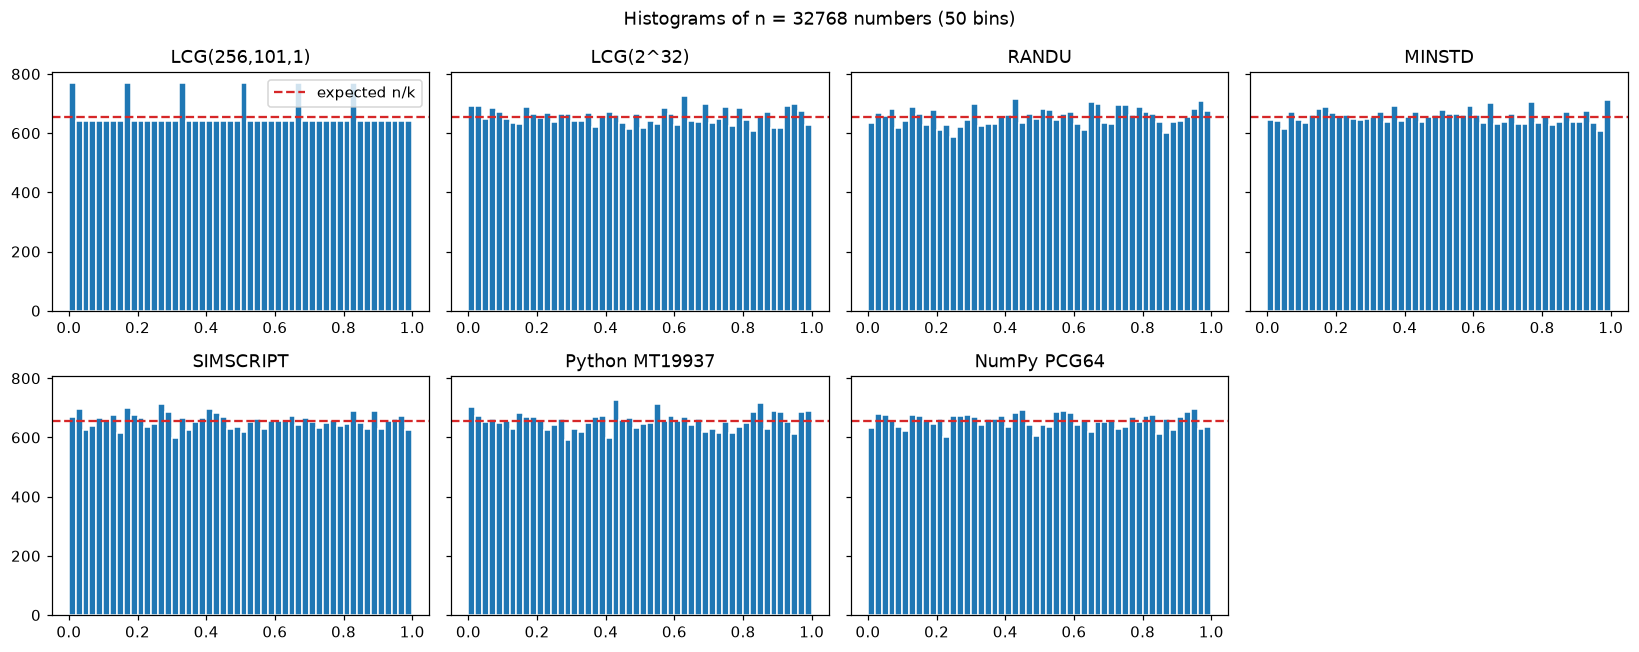

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharey=True)
for ax, (name, x) in zip(axes.ravel(), samples.items()):
    ax.hist(x, bins=50, range=(0, 1), color="tab:blue", edgecolor="white")
    ax.axhline(N / 50, color="tab:red", ls="--", label="expected n/k")
    ax.set_title(name)
for ax in axes.ravel()[len(samples):]:
    ax.set_visible(False)
axes[0, 0].legend()
fig.suptitle(f"Histograms of n = {N} numbers (50 bins)")
fig.tight_layout()

## 3–4. Statistical testing: Chi-square uniformity test

Split $[0,1)$ into $k$ equal intervals ($k > 100$, $n/k \ge 5$), count $f_j$ numbers in interval $j$:

$$\chi^2 = \frac{k}{n} \sum_{j=1}^{k} \left(f_j - \frac{n}{k}\right)^2 \;\sim\; \chi^2_{k-1} \quad \text{under } H_0: U_i \text{ iid } U(0,1)$$

Reject $H_0$ when $\chi^2 > \chi^2_{k-1,\,1-\alpha}$.

**Slides' example**: SIMSCRIPT generator, $k = 2^{12} = 4096$, $n = 2^{15} = 32768$, $\alpha = 0.10$: $\chi^2 = 4141 < \chi^2_{4095,\,0.90} = 4211.4$, so $H_0$ is accepted. The seed used in the slides is unknown, so our statistic differs, but the critical value must match.

In [12]:
k, n, alpha = 2**12, 2**15, 0.10
res = chi_square_uniformity(simscript().uniforms(n), k, alpha)
print("SIMSCRIPT:", res)
assert abs(res.critical - 4211.4) < 0.5          # critical value of the slides

SIMSCRIPT: chi2 = 4071.2  df = 4095  chi2_crit(1-0.1) = 4211.4  p = 0.6009  ->  accept H0


In [13]:
chi_results = {name: chi_square_uniformity(x, k, alpha) for name, x in samples.items()}
for name, r in chi_results.items():
    print(f"{name:16s} {r}")

LCG(256,101,1)   chi2 = 491520.0  df = 4095  chi2_crit(1-0.1) = 4211.4  p = 0.0000  ->  REJECT H0
LCG(2^32)        chi2 = 4116.8  df = 4095  chi2_crit(1-0.1) = 4211.4  p = 0.4023  ->  accept H0
RANDU            chi2 = 4325.0  df = 4095  chi2_crit(1-0.1) = 4211.4  p = 0.0062  ->  REJECT H0
MINSTD           chi2 = 4198.0  df = 4095  chi2_crit(1-0.1) = 4211.4  p = 0.1280  ->  accept H0
SIMSCRIPT        chi2 = 4071.2  df = 4095  chi2_crit(1-0.1) = 4211.4  p = 0.6009  ->  accept H0
Python MT19937   chi2 = 4140.5  df = 4095  chi2_crit(1-0.1) = 4211.4  p = 0.3056  ->  accept H0
NumPy PCG64      chi2 = 4101.0  df = 4095  chi2_crit(1-0.1) = 4211.4  p = 0.4707  ->  accept H0


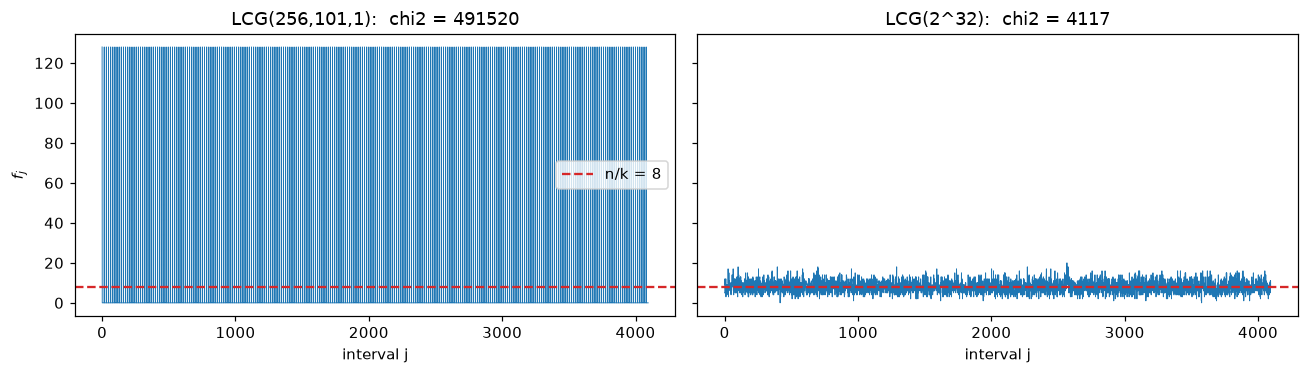

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, name in zip(axes, ["LCG(256,101,1)", "LCG(2^32)"]):
    r = chi_results[name]
    ax.plot(r.freqs, lw=0.6)
    ax.axhline(r.expected, color="tab:red", ls="--", label=f"n/k = {r.expected:.0f}")
    ax.set_title(f"{name}:  chi2 = {r.statistic:.0f}")
    ax.set_xlabel("interval j")
axes[0].set_ylabel("$f_j$")
axes[0].legend()
fig.tight_layout()

**Interpretation.** `LCG(256,101,1)` only produces 256 distinct values, so at most 256 of the 4096 intervals can ever be hit: the test rejects it immediately ($\chi^2 \approx 491520$).

With seed 1, RANDU's first block is also rejected ($p \approx 0.006$). One test is not enough to decide, though: at $\alpha = 0.10$ even a perfect generator is rejected 10 % of the time.

### Repeating the test

To separate a real defect from bad luck, the test is repeated. Repeating it on $R = 100$ consecutive, disjoint blocks of each generator, under $H_0$ the p-values should be $U(0,1)$ and the rejection rate close to $\alpha$:

generator        rejection rate (expected 0.10)
LCG(256,101,1)   1.00
LCG(2^32)        0.16
RANDU            0.07
MINSTD           0.09
SIMSCRIPT        0.11
Python MT19937   0.12
NumPy PCG64      0.08


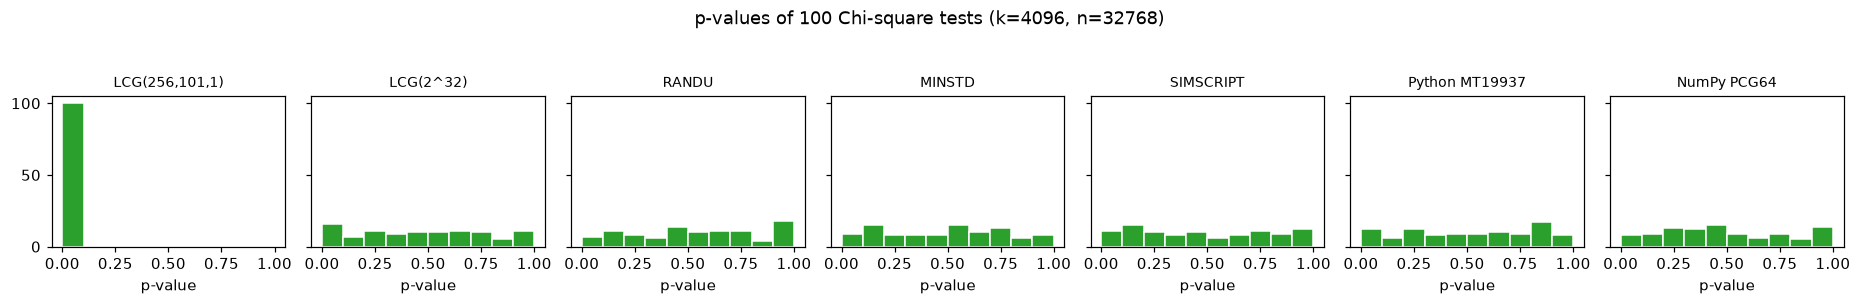

In [15]:
R = 100
pvals = {}
for name, gen in GENERATORS.items():
    x = gen(R * n).reshape(R, n)
    pvals[name] = np.array([chi_square_uniformity(row, k, alpha).p_value for row in x])

print(f"{'generator':16s} rejection rate (expected {alpha:.2f})")
for name, p in pvals.items():
    print(f"{name:16s} {np.mean(p < alpha):.2f}")

fig, axes = plt.subplots(1, len(pvals), figsize=(17, 2.6), sharey=True)
for ax, (name, p) in zip(axes, pvals.items()):
    ax.hist(p, bins=10, range=(0, 1), color="tab:green", edgecolor="white")
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("p-value")
fig.suptitle(f"p-values of {R} Chi-square tests (k={k}, n={n})", y=1.05)
fig.tight_layout()

Every generator except the toy LCG is rejected in about $\alpha = 10\%$ of the blocks, **RANDU included**. Its single rejection above was bad luck. A one-dimensional uniformity test looks at each number on its own, so it cannot detect correlations between successive numbers. Section 5 shows that RANDU's defect is exactly of that kind.

### Chi-square variants: serial, gap and runs tests

**Serial test** (Chi-square in $d$ dimensions). The stream is split into non-overlapping vectors $U_1 = (u_1,\dots,u_d)$, $U_2 = (u_{d+1},\dots,u_{2d}), \dots$ and $[0,1)^d$ into $k^d$ equal cells. With $n$ vectors,
$$\chi^2(d) = \frac{k^d}{n} \sum_{j_1=1}^{k}\cdots\sum_{j_d=1}^{k} \left(f_{j_1 \dots j_d} - \frac{n}{k^d}\right)^2 \sim \chi^2_{k^d-1}.$$
Slides' example: $d=2$, $k=64$, $32768$ pairs, $df = 64^2 - 1 = 4095$, $\chi^2_{0.90} = 4211.4$. We also use $d=3$, $k=16$ ($4096$ cells, $32768$ triples).

**Gap test**. For an interval $[a,b)$ with $p = b-a$, the gap length $r$ (number of values outside $[a,b)$ between two consecutive values inside it) is geometric under $H_0$: $P(r) = p(1-p)^r$ for $r < t$ and $P(r \ge t) = (1-p)^t$. Chi-square with $t+1$ classes ($df = t$). We use the slides' interval $[0.4, 0.7)$ and $t = 10$. In the slides' example (0.1, 0.5, 0.9, 0.6 …) the "distance" 2 between 0.5 and 0.6 is a gap of length 1.

**Runs-up test** (independence, not uniformity). The sequence is cut into ascending runs. With $r_1..r_5$ the number of runs of length $1..5$ and $r_6$ the number of length $\ge 6$,
$$R = \frac{1}{n}\sum_{i=1}^{6}\sum_{j=1}^{6} a_{ij}(r_i - n b_i)(r_j - n b_j) \sim \chi^2_6 \quad (n \ge 4000),$$
with Knuth's constants $a_{ij}$ and $b = (\tfrac16, \tfrac5{24}, \tfrac{11}{120}, \tfrac{19}{720}, \tfrac{29}{5040}, \tfrac1{840})$.

**Validation on the slides' examples:**

In [16]:
example = [0.86, 0.11, 0.23, 0.03, 0.13, 0.06, 0.55, 0.64, 0.87, 0.10]
print("runs up r_1..r_6 :", runs_up_counts(example), " (slides: 2 2 0 1 0 0)")
assert list(runs_up_counts(example)) == [2, 2, 0, 1, 0, 0]

print("gap lengths      :", gap_lengths(np.array([0.1, 0.5, 0.9, 0.6]), 0.4, 0.7),
      " (slides: distance 2 = gap length 1)")

pairs = 2**15
r = serial_test(numpy_random(2 * pairs), k=64, d=2)
print("serial d=2 df / critical value:", r.df, round(r.critical, 1), " (slides: 4095, 4211.4)")
assert r.df == 4095 and abs(r.critical - 4211.4) < 0.5

runs up r_1..r_6 : [2 2 0 1 0 0]  (slides: 2 2 0 1 0 0)
gap lengths      : [1]  (slides: distance 2 = gap length 1)
serial d=2 df / critical value: 4095 4211.4  (slides: 4095, 4211.4)


### The battery of tests on every generator

Each test uses the first $3 \cdot 2^{15} = 98304$ numbers of the generator (seed 1), at $\alpha = 0.10$:

In [17]:
TESTS = {
    "chi2 1D (k=4096)":   lambda x: chi_square_uniformity(x[:2**15], k=4096),
    "serial d=2 (k=64)":  lambda x: serial_test(x[:2 * 2**15], k=64, d=2),
    "serial d=3 (k=16)":  lambda x: serial_test(x[:3 * 2**15], k=16, d=3),
    "gap [0.4,0.7) t=10": lambda x: gap_test(x, 0.4, 0.7, t=10),
    "runs up":            lambda x: runs_up_test(x),
}
N_BATTERY = 3 * 2**15
battery = {name: gen(N_BATTERY) for name, gen in GENERATORS.items()}

print(f"{'p-values':16s}" + "".join(f"{t:>20s}" for t in TESTS))
for name, x in battery.items():
    row = [TESTS[t](x).p_value for t in TESTS]
    print(f"{name:16s}" + "".join(f"{p:19.4f}{'*' if p < alpha else ' '}" for p in row))
print("* = rejected at alpha = 0.10")

p-values            chi2 1D (k=4096)   serial d=2 (k=64)   serial d=3 (k=16)  gap [0.4,0.7) t=10             runs up
LCG(256,101,1)               0.0000*             0.0000*             0.0000*             0.0000*             0.0000*
LCG(2^32)                    0.4023              0.5521              0.3421              0.8693              0.8584 
RANDU                        0.0062*             0.5037              0.0000*             0.9466              0.0550*
MINSTD                       0.1280              0.6094              0.0549*             0.3213              0.1556 
SIMSCRIPT                    0.6009              0.6806              0.8005              0.5623              0.5152 
Python MT19937               0.3056              0.2195              0.9131              0.0632*             0.2732 
NumPy PCG64                  0.4707              0.0340*             0.6964              0.7206              0.1816 
* = rejected at alpha = 0.10


As with the 1D test, one run is not conclusive, so each test is repeated on $R = 100$ disjoint blocks of each generator. A good generator should be rejected in about 10 % of them:

In [18]:
R = 100
reject_rate = {}
for name, gen in GENERATORS.items():
    blocks = gen(R * N_BATTERY).reshape(R, N_BATTERY)
    reject_rate[name] = {t: np.mean([test(b).p_value < alpha for b in blocks]) for t, test in TESTS.items()}

print(f"{'rejection rate':16s}" + "".join(f"{t:>20s}" for t in TESTS))
for name, rates in reject_rate.items():
    print(f"{name:16s}" + "".join(f"{rates[t]:20.2f}" for t in TESTS))
print(f"(expected {alpha:.2f} for a good generator)")

rejection rate      chi2 1D (k=4096)   serial d=2 (k=64)   serial d=3 (k=16)  gap [0.4,0.7) t=10             runs up
LCG(256,101,1)                  1.00                1.00                1.00                1.00                1.00
LCG(2^32)                       0.13                0.08                0.07                0.06                0.08
RANDU                           0.12                0.03                1.00                0.06                0.23
MINSTD                          0.09                0.11                0.12                0.09                0.12
SIMSCRIPT                       0.13                0.15                0.11                0.14                0.14
Python MT19937                  0.14                0.11                0.09                0.12                0.09
NumPy PCG64                     0.11                0.09                0.06                0.06                0.11
(expected 0.10 for a good generator)


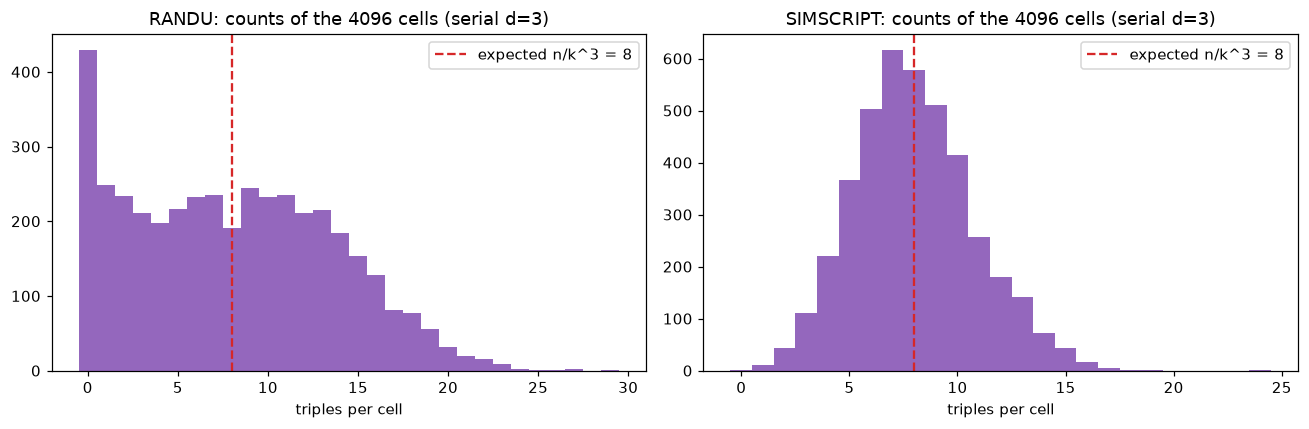

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, ("RANDU", "SIMSCRIPT")):
    res = TESTS["serial d=3 (k=16)"](battery[name])
    ax.hist(res.freqs, bins=np.arange(res.freqs.max() + 2) - 0.5, color="tab:purple")
    ax.axvline(res.expected, color="tab:red", ls="--", label=f"expected n/k^3 = {res.expected:.0f}")
    ax.set_title(f"{name}: counts of the 4096 cells (serial d=3)")
    ax.set_xlabel("triples per cell")
    ax.legend()
fig.tight_layout()

**Interpretation**

* The toy `LCG(256,101,1)` fails every test.
* **RANDU** passes the 1D and 2D Chi-square tests and the gap test at about the nominal rate, but:
  * the **3D serial test rejects it in every block** (100 %). Its triples lie on 15 planes, so many of the $16^3$ cells stay (almost) empty while others are overfull. This is the same defect the spectral test finds in Section 5, now detected empirically.
  * the **runs-up test** rejects it in 23 % of the blocks, more than twice the nominal 10 % (with 100 blocks the standard error is about 3 %, so this is not chance). The dependence between consecutive RANDU numbers also shows up as a weaker signal in the ordering of the values.
* MINSTD, SIMSCRIPT, MT19937 and PCG64 are rejected in 6–15 % of the blocks in every test. That is consistent with the nominal 10 % at this number of repetitions, as expected from good generators.
* Empirical tests only detect defects at the resolution they look at: MINSTD's 2D lattice (planes $6\cdot 10^{-5}$ apart) is far too fine to show up on a $64 \times 64$ grid.

## 5. Spectral analysis: lattice structure

Marsaglia (1968): *random numbers fall mainly in the planes*. The overlapping $t$-tuples $(u_i, \dots, u_{i+t-1})$ of an LCG lie on parallel hyperplanes $s \cdot u \equiv \text{const} \pmod 1$, with $s$ a nonzero integer vector of the **dual lattice**

$$L^*_t = \{ s \in \mathbb{Z}^t : s_1 + s_2 a + \dots + s_t a^{t-1} \equiv 0 \pmod m \}.$$

The spectral test computes $\nu_t = \min_{s \in L^*_t \setminus 0} \lVert s \rVert$ (exactly: LLL reduction + Fincke–Pohst enumeration) and reports

* $d_t = 1/\nu_t$: maximum distance between adjacent hyperplanes (**small = good**),
* $S_t = \nu_t / (\gamma_t^{1/2} m^{1/t})$: normalised value in $(0,1]$ (**close to 1 = good**).

**Validation against the slides**: LCG$(256, a, 1, 0)$ with $a = 85, 101, 61, 237$ has spectral values $0.3162, 0.1162, 0.0790, 0.0632$ and normalised values $0.1839, 0.5003, 0.7357, 0.9196$.

In [20]:
slides_d = {85: 0.3162, 101: 0.1162, 61: 0.0790, 237: 0.0632}
slides_S = {85: 0.1839, 101: 0.5003, 61: 0.7357, 237: 0.9196}

print(f"{'a':>4} | {'d_2':>7} {'slides':>7} | {'S_2':>7} {'slides':>7} | s")
for a in slides_d:
    r = spectral_test(256, a, 2)
    print(f"{a:4d} | {r.d:7.4f} {slides_d[a]:7.4f} | {r.S:7.4f} {slides_S[a]:7.4f} | {r.s}")
    assert abs(r.d - slides_d[a]) < 1e-4 and abs(r.S - slides_S[a]) < 1e-4

    # brute-force check of the shortest dual vector for this small m
    best = min(s1*s1 + s2*s2 for s1 in range(-256, 257) for s2 in range(-256, 257)
               if (s1 or s2) and (s1 + a * s2) % 256 == 0)
    assert best == round(r.nu ** 2)
print("matches the slides and brute force")

   a |     d_2  slides |     S_2  slides | s
  85 |  0.3162  0.3162 |  0.1839  0.1839 | [1, 3]
 101 |  0.1162  0.1162 |  0.5003  0.5003 | [7, 5]
  61 |  0.0791  0.0790 |  0.7357  0.7357 | [12, 4]
 237 |  0.0632  0.0632 |  0.9196  0.9196 | [9, -13]
matches the slides and brute force


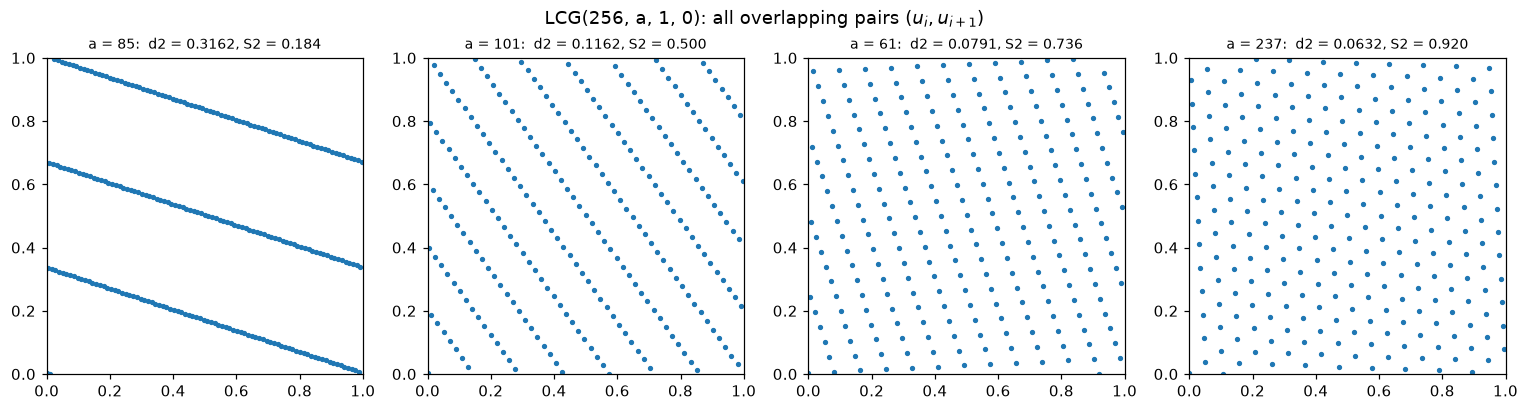

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, a in zip(axes, slides_d):
    u = LCG(256, a, 1, 0).uniforms(256)            # one full period
    pairs = overlapping_tuples(np.r_[u, u[0]], 2)
    r = spectral_test(256, a, 2)
    ax.scatter(pairs[:, 0], pairs[:, 1], s=6, color="tab:blue")
    ax.set_title(f"a = {a}:  d2 = {r.d:.4f}, S2 = {r.S:.3f}", fontsize=9)
    ax.set_aspect("equal")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
fig.suptitle("LCG(256, a, 1, 0): all overlapping pairs $(u_i, u_{i+1})$")
fig.tight_layout()

### Spectral test of the real generators, dimensions 2 to 6

In [22]:
spectral = {}
print(f"{'generator':10s} {'t':>2} | {'d_t':>10} {'S_t':>6} | max #hyperplanes | s")
for make in (lcg32, randu, minstd, simscript):
    g = make()
    for t in range(2, 7):
        r = spectral_test(g.m, g.a, t)
        spectral[(g.name, t)] = r
        print(f"{g.name:10s} {t:2d} | {r.d:10.3e} {r.S:6.3f} | {r.max_hyperplanes:16d} | {r.s}")
    print()

generator   t |        d_t    S_t | max #hyperplanes | s
LCG(2^32)   2 |  1.423e-05  0.998 |            98772 | [54907, 43865]
LCG(2^32)   3 |  6.562e-04  0.835 |             2280 | [133, 1073, -1074]
LCG(2^32)   4 |  3.962e-03  0.829 |              448 | [116, 32, 196, 104]
LCG(2^32)   5 |  1.563e-02  0.615 |              122 | [17, -12, 9, -47, 37]
LCG(2^32)   6 |  3.104e-02  0.619 |               58 | [2, 4, -3, -28, 12, 9]

RANDU       2 |  2.158e-05  0.931 |            65532 | [32765, -32767]
RANDU       3 |  9.206e-02  0.008 |               16 | [9, -6, 1]
RANDU       4 |  9.285e-02  0.042 |               18 | [9, 3, -5, 1]
RANDU       5 |  9.285e-02  0.119 |               18 | [9, 3, -5, 1, 0]
RANDU       6 |  9.285e-02  0.232 |               18 | [9, 3, -5, 1, 0, 0]

MINSTD      2 |  5.950e-05  0.338 |            16808 | [16807, -1]
MINSTD      3 |  1.565e-03  0.441 |              765 | [90, -44, 631]
MINSTD      4 |  6.791e-03  0.575 |              272 | [98, -89, 26, 59]
MINS

Knuth's rule of thumb: a multiplier passes the spectral test if $S_t \ge 0.1$ for $2 \le t \le 6$.

* **RANDU** fails badly: $S_3 \approx 0.0075$. All its triples satisfy $9u_i - 6u_{i+1} + u_{i+2} \in \mathbb{Z}$, so they lie on (at most) 15 planes.
* **MINSTD** passes, but is weak in 2D ($S_2 \approx 0.34$, $s = (16807, -1)$: the almost vertical lines of the slides, $1/16807 \approx 6\cdot10^{-5}$ apart).
* **SIMSCRIPT** passes and is much better in 2D ($S_2 \approx 0.82$), but no better than MINSTD in 3D ($S_3 \approx 0.43$).

(These values agree with Knuth, TAOCP vol. 2, §3.3.4, Table 1.)

### RANDU in 3D: the 15 planes

Looking along a direction perpendicular to $s$ makes the planes edge-on. The projection $s \cdot u$ takes only integer values.

distinct values of s.u for RANDU: [-5 -4 -3 -2 -1  0  1  2  3  4  5  6  7  8  9] -> 15 planes


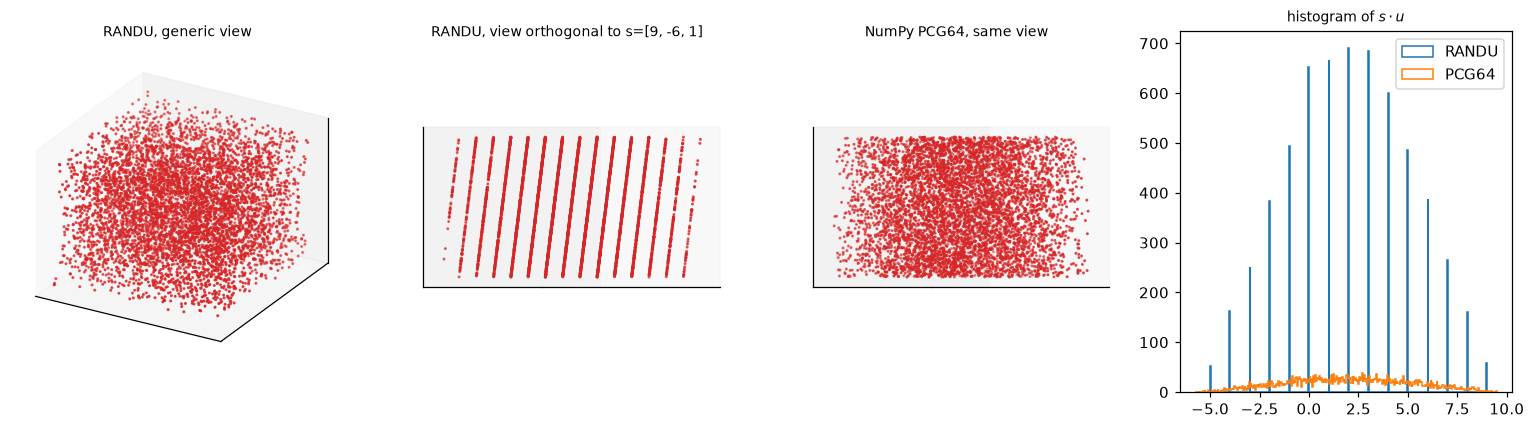

In [23]:
s = spectral[("RANDU", 3)].s
azim = degrees(atan2(s[0], -s[1]))          # camera direction orthogonal to s

def plot_triples(ax, u, title, view):
    tr = overlapping_tuples(u, 3)
    ax.scatter(tr[:, 0], tr[:, 1], tr[:, 2], s=1, color="tab:red")
    ax.view_init(*view)
    ax.set_title(title, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

u_randu = randu().uniforms(6_000)
u_numpy = numpy_random(6_000)

fig = plt.figure(figsize=(14, 4))
plot_triples(fig.add_subplot(141, projection="3d", proj_type="ortho"), u_randu, "RANDU, generic view", (25, -60))
plot_triples(fig.add_subplot(142, projection="3d", proj_type="ortho"), u_randu, f"RANDU, view orthogonal to s={s}", (0, azim))
plot_triples(fig.add_subplot(143, projection="3d", proj_type="ortho"), u_numpy, "NumPy PCG64, same view", (0, azim))

ax = fig.add_subplot(144)
for u, lab in ((u_randu, "RANDU"), (u_numpy, "PCG64")):
    proj = overlapping_tuples(u, 3) @ np.array(s, dtype=float)
    ax.hist(proj, bins=400, histtype="step", label=lab)
ax.set_title("histogram of $s \\cdot u$", fontsize=9)
ax.legend()
fig.tight_layout()

proj = overlapping_tuples(u_randu, 3) @ np.array(s, dtype=float)
planes = np.unique(np.round(proj, 6))
print("distinct values of s.u for RANDU:", planes.astype(int), "->", len(planes), "planes")

### Zooming in: MINSTD vs SIMSCRIPT in 2D

The slides zoom into $[0.4995, 0.5005]^2$. Every pair $(Z, aZ \bmod m)/m$ of the full period that falls in that window can be enumerated directly (the period covers all $Z = 1, \dots, m-1$ because $a$ is a primitive root of $m$):

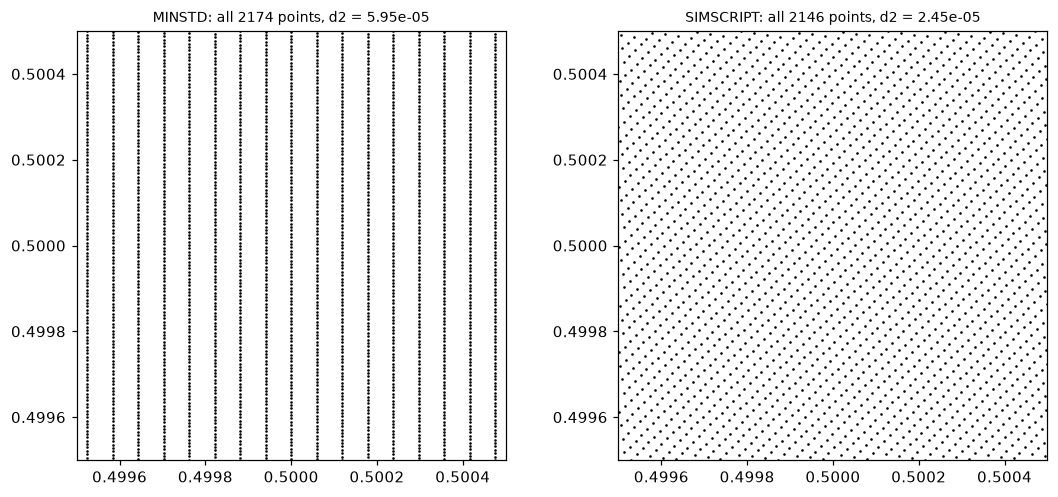

In [24]:
def is_primitive_root(a, m):
    return all(pow(a, (m - 1) // q, m) != 1 for q in prime_factors(m - 1))

lo, hi = 0.4995, 0.5005
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
for ax, make in zip(axes, (minstd, simscript)):
    g = make()
    assert is_primitive_root(g.a, g.m)                  # period m-1: every Z appears
    Z = np.arange(int(lo * g.m), int(hi * g.m) + 1, dtype=np.int64)
    Z2 = (g.a * Z) % g.m
    keep = (Z2 >= lo * g.m) & (Z2 <= hi * g.m)
    ax.scatter(Z[keep] / g.m, Z2[keep] / g.m, s=0.5, color="black")
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
    ax.set_title(f"{g.name}: all {keep.sum()} points, d2 = {spectral[(g.name, 2)].d:.2e}", fontsize=9)
fig.tight_layout()

## 6. Custom generators vs the native RNGs

In [25]:
def time_per_million(gen):
    t0 = time.perf_counter()
    gen(1_000_000)
    return time.perf_counter() - t0

periods = {"LCG(256,101,1)": LCG(256, 101, 1, 0).period(), "LCG(2^32)": "2^32", "RANDU": "2^29",
           "MINSTD": "2^31-2", "SIMSCRIPT": "2^31-2",
           "Python MT19937": "2^19937-1", "NumPy PCG64": "2^128"}

print(f"{'generator':16s} {'period':>10s} | {'chi2 p':>7s} {'reject%':>8s} | {'d_2':>9s} {'d_3':>9s} {'S_3':>6s} | {'s/1e6':>6s}")
for name, gen in GENERATORS.items():
    r = chi_results[name]
    if (name, 2) in spectral:
        d2, d3, S3 = spectral[(name, 2)].d, spectral[(name, 3)].d, spectral[(name, 3)].S
        spec = f"{d2:9.2e} {d3:9.2e} {S3:6.3f}"
    elif name == "LCG(256,101,1)":
        r2, r3 = spectral_test(256, 101, 2), spectral_test(256, 101, 3)
        spec = f"{r2.d:9.2e} {r3.d:9.2e} {r3.S:6.3f}"
    else:
        spec = f"{'n/a (not an LCG)':>26s}"
    print(f"{name:16s} {str(periods[name]):>10s} | {r.p_value:7.4f} {100*np.mean(pvals[name] < alpha):7.0f}% | {spec} | {time_per_million(gen):6.3f}")

generator            period |  chi2 p  reject% |       d_2       d_3    S_3 |  s/1e6
LCG(256,101,1)          256 |  0.0000     100% |  1.16e-01  2.36e-01  0.595 |  0.034
LCG(2^32)              2^32 |  0.4023      16% |  1.42e-05  6.56e-04  0.835 |  0.036
RANDU                  2^29 |  0.0062       7% |  2.16e-05  9.21e-02  0.008 |  0.034
MINSTD               2^31-2 |  0.1280       9% |  5.95e-05  1.57e-03  0.441 |  0.038
SIMSCRIPT            2^31-2 |  0.6009      11% |  2.45e-05  1.60e-03  0.432 |  0.033
Python MT19937    2^19937-1 |  0.3056      12% |           n/a (not an LCG) |  0.158
NumPy PCG64           2^128 |  0.4707       8% |           n/a (not an LCG) |  0.006


**Conclusions**

* **Period**: the toy LCG repeats after 256 numbers and fails everything. The 31-bit LCGs repeat after ~$2\cdot10^9$ numbers, which a modern simulation can exhaust in seconds; MT19937 and PCG64 have astronomically long periods.
* **Uniformity (Chi-square)**: over 100 repetitions, every generator except the toy LCG is rejected at close to the nominal rate $\alpha$, as a uniform generator should be. A single test can still reject a good generator by chance (RANDU, seed 1).
* **Chi-square variants**: the gap test finds nothing wrong with any 31-bit LCG. The runs-up test weakly flags RANDU (23 % rejection), and the **3D serial test** catches it decisively (100 %) because it looks at triples. MINSTD and SIMSCRIPT pass every empirical test. Passing a 1D uniformity test is necessary but **not sufficient**.
* **Lattice structure (spectral test)**: RANDU passes Chi-square but is catastrophic in 3D (15 planes, $S_3 \approx 0.0075$). MINSTD has a coarse 2D lattice ($S_2 \approx 0.34$). SIMSCRIPT is the best of the three LCGs in 2D, similar to MINSTD in 3D. The spectral test is not defined for MT19937/PCG64 (not LCGs), and their 3D plots show no planes.
* **Speed**: the vectorised LCGs and NumPy are fast; pure-Python generation (`random.random` in a loop) is the slowest.
* Recommendation: use the language's native generator (NumPy PCG64) for real simulations; LCGs are useful to understand how PRNGs work and how they fail.

## 7. The Drunkard's Walk (2D and 3D)

A drunkard leaves the lamppost (the origin) and at each step moves one unit along one of the $2d$ axis directions, each with probability $1/(2d)$, chosen from a uniform number as $\lfloor 2d\,u \rfloor$.

Known results used to validate the simulation:

* $E\lVert X_N\rVert^2 = N$ in every dimension (RMS distance $\sqrt N$);
* $E\lVert X_N\rVert \approx \sqrt{2N/d}\;\Gamma(\tfrac{d+1}{2})/\Gamma(\tfrac d2)$: $0.886\sqrt N$ in 2D, $0.921\sqrt N$ in 3D;
* for large $N$, $\lVert X_N\rVert / \sqrt{N/d}$ follows a $\chi_d$ distribution;
* **Pólya's theorem**: the walk returns to the origin with probability 1 in 2D (recurrent) but only $\approx 0.3405$ in 3D (transient).

Each walker gets its own non-overlapping substream of the SIMSCRIPT generator (jump-ahead), and the same experiment is repeated with NumPy's PCG64.

In [26]:
W, STEPS = 2_000, 10_000
walks = {}
for dim in (2, 3):
    lcg_source = LCGStreams(simscript(seed=12345), n_streams=W, block_len=STEPS)
    rng = np.random.default_rng(12345)
    t0 = time.perf_counter()
    walks[("SIMSCRIPT", dim)] = simulate_walks(lcg_source, W, STEPS, dim)
    walks[("PCG64", dim)] = simulate_walks(lambda w, l: rng.random((w, l)), W, STEPS, dim)
    print(f"{dim}D: {W} walkers x {STEPS} steps x 2 generators in {time.perf_counter() - t0:.1f} s")

2D: 2000 walkers x 10000 steps x 2 generators in 4.5 s
3D: 2000 walkers x 10000 steps x 2 generators in 5.5 s


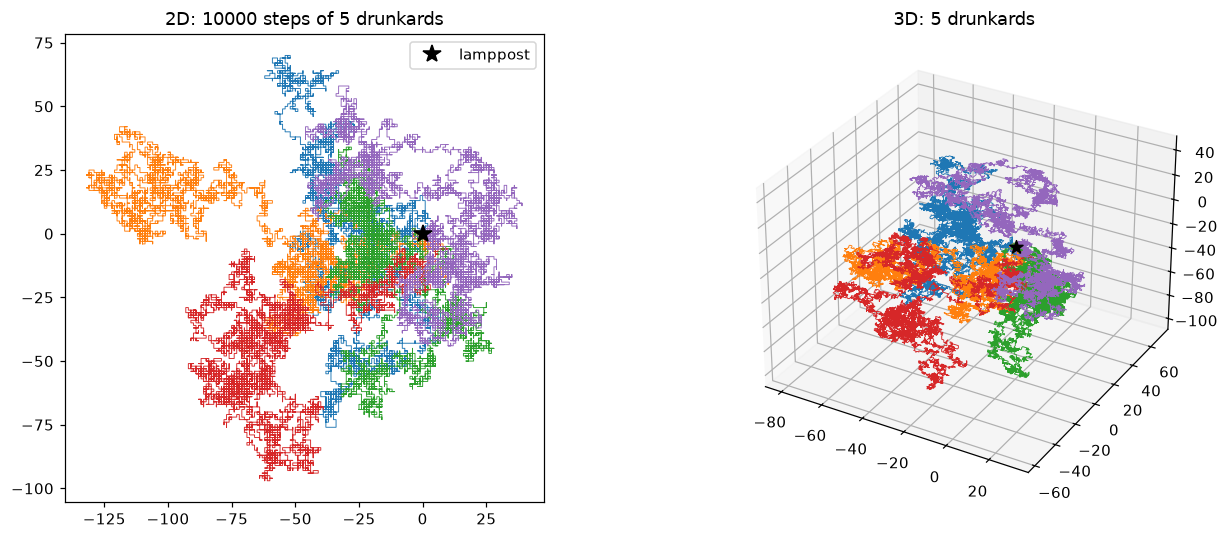

In [27]:
fig = plt.figure(figsize=(13, 5))
ax = fig.add_subplot(121)
for p in walks[("SIMSCRIPT", 2)].paths:
    ax.plot(p[:, 0], p[:, 1], lw=0.6)
ax.plot(0, 0, "k*", ms=12, label="lamppost")
ax.set_aspect("equal"); ax.legend()
ax.set_title(f"2D: {STEPS} steps of 5 drunkards")

ax = fig.add_subplot(122, projection="3d")
for p in walks[("SIMSCRIPT", 3)].paths:
    ax.plot(p[:, 0], p[:, 1], p[:, 2], lw=0.6)
ax.scatter(0, 0, 0, color="k", marker="*", s=80)
ax.set_title("3D: 5 drunkards")
fig.tight_layout()

2D SIMSCRIPT: E|X|^2/N = 0.993 (theory 1)   E|X| =  88.29 (theory  88.62)
2D PCG64    : E|X|^2/N = 1.009 (theory 1)   E|X| =  88.56 (theory  88.62)
3D SIMSCRIPT: E|X|^2/N = 1.008 (theory 1)   E|X| =  92.61 (theory  92.13)
3D PCG64    : E|X|^2/N = 0.990 (theory 1)   E|X| =  91.63 (theory  92.13)


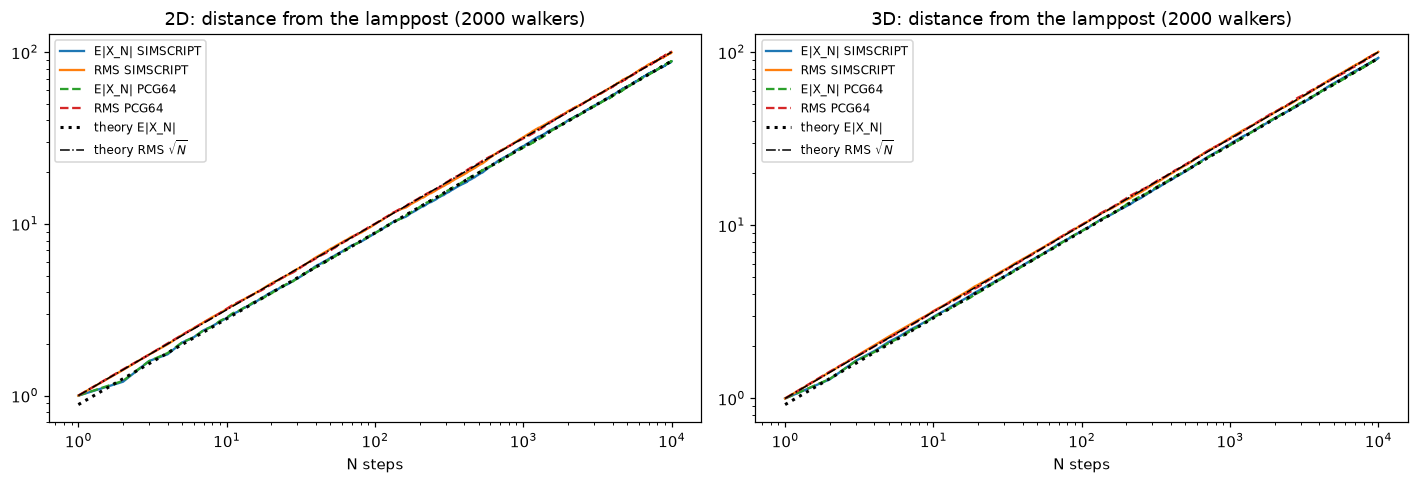

In [28]:
t = np.arange(STEPS + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for dim, ax in zip((2, 3), axes):
    for gen, style in (("SIMSCRIPT", "-"), ("PCG64", "--")):
        w = walks[(gen, dim)]
        ax.loglog(t[1:], w.mean_dist[1:], style, label=f"E|X_N| {gen}")
        ax.loglog(t[1:], np.sqrt(w.mean_sq_dist[1:]), style, label=f"RMS {gen}")
    ax.loglog(t[1:], expected_mean_distance(t[1:], dim), "k:", lw=2, label="theory E|X_N|")
    ax.loglog(t[1:], np.sqrt(t[1:]), "k-.", lw=1, label=r"theory RMS $\sqrt{N}$")
    ax.set_title(f"{dim}D: distance from the lamppost ({W} walkers)")
    ax.set_xlabel("N steps")
    ax.legend(fontsize=8)
fig.tight_layout()

for (gen, dim), w in walks.items():
    print(f"{dim}D {gen:9s}: E|X|^2/N = {w.mean_sq_dist[-1] / STEPS:.3f} (theory 1)   "
          f"E|X| = {w.mean_dist[-1]:6.2f} (theory {expected_mean_distance(STEPS, dim):6.2f})")

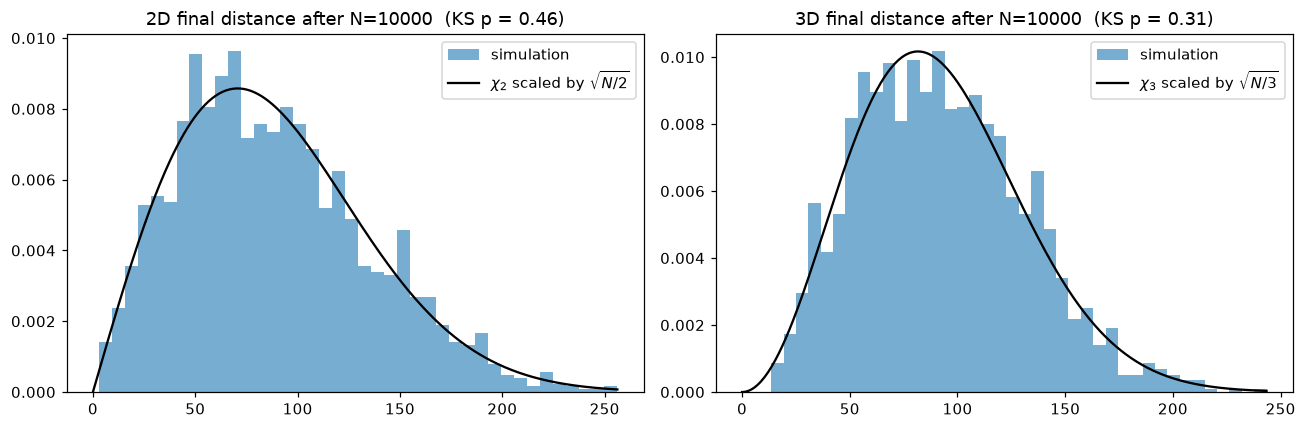

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for dim, ax in zip((2, 3), axes):
    dist = np.linalg.norm(walks[("SIMSCRIPT", dim)].final, axis=1)
    scale = np.sqrt(STEPS / dim)
    ax.hist(dist, bins=40, density=True, alpha=0.6, label="simulation")
    x = np.linspace(0, dist.max(), 300)
    ax.plot(x, stats.chi.pdf(x, df=dim, scale=scale), "k", label=fr"$\chi_{dim}$ scaled by $\sqrt{{N/{dim}}}$")
    ks = stats.kstest(dist, stats.chi(df=dim, scale=scale).cdf)
    ax.set_title(f"{dim}D final distance after N={STEPS}  (KS p = {ks.pvalue:.2f})")
    ax.legend()
fig.tight_layout()

### Does the drunkard come back? (Pólya)

2D SIMSCRIPT: returned within 10000 steps = 0.743
2D PCG64    : returned within 10000 steps = 0.745
3D SIMSCRIPT: returned within 10000 steps = 0.324
3D PCG64    : returned within 10000 steps = 0.329


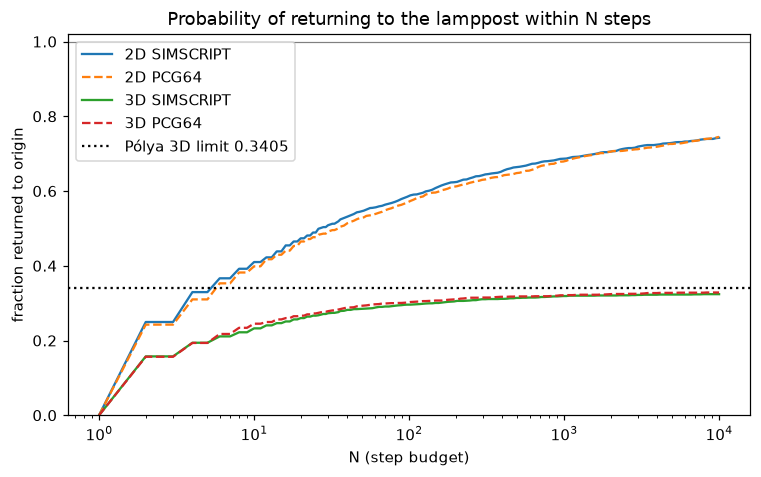

In [30]:
budgets = np.unique(np.logspace(0, np.log10(STEPS), 200).astype(int))
fig, ax = plt.subplots(figsize=(8, 4.5))
for (gen, dim), w in walks.items():
    ax.semilogx(budgets, w.return_fraction(budgets), "-" if gen == "SIMSCRIPT" else "--",
                label=f"{dim}D {gen}")
ax.axhline(POLYA_3D, color="k", ls=":", label=f"Pólya 3D limit {POLYA_3D:.4f}")
ax.axhline(1, color="gray", lw=0.8)
ax.set_xlabel("N (step budget)")
ax.set_ylabel("fraction returned to origin")
ax.set_ylim(0, 1.02)
ax.legend()
ax.set_title("Probability of returning to the lamppost within N steps")

for (gen, dim), w in walks.items():
    print(f"{dim}D {gen:9s}: returned within {STEPS} steps = {w.return_fraction([STEPS])[0]:.3f}")

### What a bad generator does to the drunkard

With `LCG(256,101,1)` the sequence of steps repeats every 256 steps, so the walk is no longer random: its displacement after each period is always the same. If that displacement is nonzero the drunkard drifts in a straight line; if it is zero (as here) they are trapped forever on the same closed 256-step circuit. There is no diffusion: the distance never grows like $\sqrt N$.

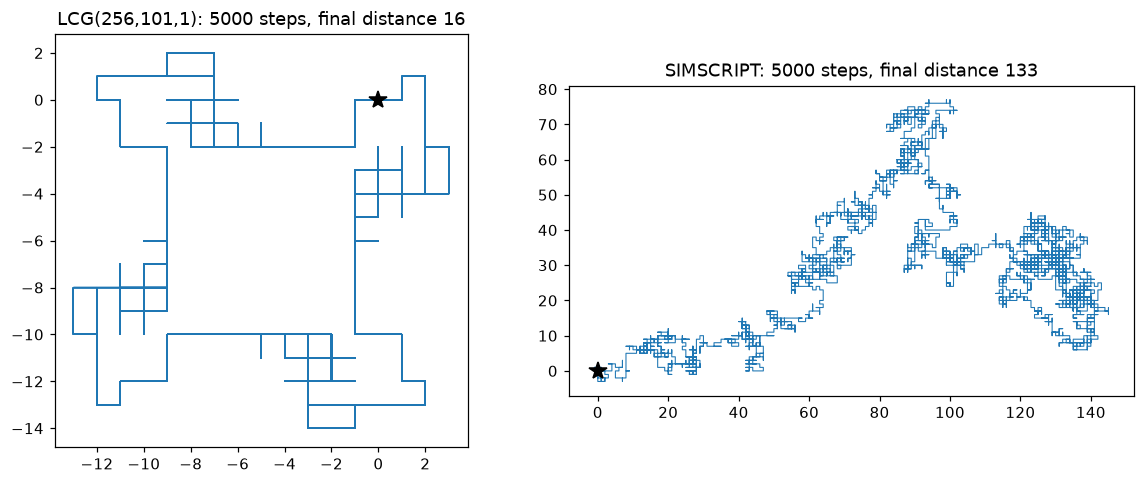

In [31]:
n_steps = 5_000
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, make) in zip(axes, (("LCG(256,101,1)", lambda: LCG(256, 101, 1, 0)),
                                   ("SIMSCRIPT", simscript))):
    g = make()
    w = simulate_walks(lambda w_, l: g.uniforms(w_ * l).reshape(w_, l), 1, n_steps, 2, keep_paths=1)
    p = w.paths[0]
    ax.plot(p[:, 0], p[:, 1], lw=0.7)
    ax.plot(0, 0, "k*", ms=12)
    ax.set_aspect("equal")
    ax.set_title(f"{name}: {n_steps} steps, final distance {np.linalg.norm(p[-1]):.0f}")
fig.tight_layout()

**Conclusions (Drunkard's walk)**

* With a good generator the mean squared distance grows **linearly** with the number of steps ($E\lVert X_N \rVert^2 = N$), so the typical distance grows like $\sqrt N$ in both 2D and 3D, matching the theoretical constants $0.886$ and $0.921$. The final distance follows the predicted $\chi_d$ law.
* **2D vs 3D**: the fraction of drunkards back at the lamppost keeps growing in 2D (recurrent walk, the limit is 1 but convergence is slow, like $1 - O(1/\ln N)$), whereas in 3D it saturates near Pólya's constant $0.34$ (transient walk: 2 out of 3 drunkards never come back).
* The SIMSCRIPT LCG and NumPy's PCG64 give statistically indistinguishable walks at this scale. A generator with a short period (`LCG(256,101,1)`) destroys the randomness of the walk completely.